# Research Notebook — Budget-Aware Importance Sampling for Variational Inference

**Research question.** *When, and for which inferential objective, does ESS-driven per-observation sample allocation outperform a uniform allocation when both methods expend the same number of target/proposal density evaluations?*

**Core hypothesis:** high-variance importance weights indicate contexts requiring more Monte Carlo samples, but a noisy pilot estimate and sample-allocation overhead may negate the gain. A secondary hypothesis asks whether improvements in evidence estimation also translate to more accurate **amortized posterior inference**.

**Historical scope:** All foundational methods in this notebook were available by **May 2022**. The proposed ESS-budget allocation and tests are independent experimental questions, **not claims of previously unpublished novelty**. A literature review is needed before making a novelty claim.

**Reproducibility.** Runs on Colab CPU. Uses fixed synthetic data seeds, repeated independent training seeds, a complete accounting of `log p(x,z)` evaluations, exact analytical posteriors for evaluation, and fresh independent pilot samples to avoid reuse of allocation data in the final estimator.

**Research artifacts generated:** posterior KL learning curves; ESS diagnostics; IWAE bounds; Monte Carlo bias/variance and convergence; paired bootstrap confidence intervals; nonlinear-likelihood stress test; IWAE inference-gradient SNR; CSV results.

**Literature:** [Burda, Grosse & Salakhutdinov, IWAE (2016)](https://arxiv.org/abs/1509.00519); [Rainforth et al., Tighter Variational Bounds are Not Necessarily Better (ICML 2018)](https://proceedings.mlr.press/v80/rainforth18b.html); [Tucker et al., Doubly Reparameterized Gradient Estimators (ICLR 2019)](https://arxiv.org/abs/1810.04152).

## 1 · Bayesian model with analytically known posterior

Take a one-dimensional latent model with three observational contexts:

\[
Z\sim\mathcal N(0,1),\qquad X\mid(Z=z,C=c)\sim\mathcal N(z,\sigma_c^2),
\qquad \sigma_c\in\{0.20,0.75,2.00\}.
\]

Bayes' rule is \(p(z\mid x,c)=p(x\mid z,c)p(z)/p(x\mid c)\). Completing the square in the Gaussian exponent gives the **exact reference posterior**

\[
\boxed{p(z\mid x,c)=\mathcal N\left(\frac{x}{1+\sigma_c^2},\frac{\sigma_c^2}{1+\sigma_c^2}\right)},\qquad
p(x\mid c)=\mathcal N(0,1+\sigma_c^2).
\]

We fit a neural **amortized Gaussian proposal** \(q_\phi(z\mid x,c)=\mathcal N(\mu_\phi(x,c),s_\phi(x,c)^2)\). Its posterior approximation quality can therefore be evaluated exactly, using the Gaussian forward and reverse KL divergences. Lower is better; units are **nats**. This removes benchmark uncertainty from numerical posterior ground truth.

In [1]:
import os, math, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
import torch
from torch import nn

# Make Colab CPU and local runs reproducible and inexpensive.
torch.set_num_threads(min(4, max(1, os.cpu_count() or 1)))
DEVICE = torch.device('cpu')
DTYPE = torch.float32
SIGMAS = np.array([0.20, 0.75, 2.00], dtype=np.float32)
POLICIES = ['uniform_K16', 'adaptive_ESS', 'shuffled_ESS', 'uniform_K12_plus_pilot']


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


def log_normal(x, mean, log_std):
    return -0.5 * ((x-mean)/torch.exp(log_std))**2 - log_std - 0.5*np.log(2*np.pi)


def generate_data(n, seed):
    rng=np.random.default_rng(seed)
    c=np.arange(n,dtype=np.int64)%len(SIGMAS)
    rng.shuffle(c)
    z=rng.normal(size=n).astype('float32')
    x=(z+SIGMAS[c]*rng.normal(size=n)).astype('float32')
    return torch.tensor(x),torch.tensor(c)


def exact_posterior(x, c):
    sigma=torch.as_tensor(SIGMAS, dtype=x.dtype,device=x.device)[c]
    v=(sigma**2)/(1+sigma**2)
    m=x/(1+sigma**2)
    return m, torch.sqrt(v)


def log_joint(z,x,c):
    sigma=torch.as_tensor(SIGMAS,dtype=x.dtype,device=x.device)[c]
    return log_normal(z,torch.zeros_like(z),torch.zeros_like(z))+log_normal(x,z,torch.log(sigma))


def exact_log_evidence(x,c):
    sigma=torch.as_tensor(SIGMAS,dtype=x.dtype,device=x.device)[c]
    return log_normal(x,torch.zeros_like(x),0.5*torch.log1p(sigma**2))


class AmortizedGaussian(nn.Module):
    def __init__(self,width=32):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(4,width),nn.Tanh(),nn.Linear(width,width),nn.Tanh(),nn.Linear(width,2))
        with torch.no_grad():
            nn.init.zeros_(self.net[-1].weight)
            nn.init.zeros_(self.net[-1].bias)
    def forward(self,x,c):
        features=torch.cat((x[:,None],torch.nn.functional.one_hot(c,3).float()),dim=1)
        out=self.net(features)
        return out[:,0],torch.clamp(out[:,1],-2.5,0.8)


def posterior_metrics(model,x,c):
    model.eval()
    with torch.no_grad():
        mu,ls=model(x,c)
        pm,ps=exact_posterior(x,c)
        qv=torch.exp(2*ls); pv=ps**2
        # KL(p || q) and KL(q || p) for Gaussian p, q
        kl_pq=0.5*(torch.log(qv/pv)+(pv+(pm-mu)**2)/qv-1)
        kl_qp=0.5*(torch.log(pv/qv)+(qv+(pm-mu)**2)/pv-1)
        e=(mu-pm)**2
        rows=[]
        for ctx in range(3):
            mask=(c==ctx)
            rows.append({'context':ctx,'n':int(mask.sum()),'forward_KL':float(kl_pq[mask].mean()),'reverse_KL':float(kl_qp[mask].mean()),'mean_rmse':float(torch.sqrt(e[mask].mean()))})
        rows.append({'context':'ALL','n':len(x),'forward_KL':float(kl_pq.mean()),'reverse_KL':float(kl_qp.mean()),'mean_rmse':float(torch.sqrt(e.mean()))})
    return pd.DataFrame(rows)


def pilot_complexity(model,x,c,K0=4):
    with torch.no_grad():
        mu,ls=model(x,c); B=len(x)
        z=mu[:,None]+torch.exp(ls)[:,None]*torch.randn(B,K0)
        logw=log_joint(z,x[:,None],c[:,None])-log_normal(z,mu[:,None],ls[:,None])
        logess=2*torch.logsumexp(logw,dim=1)-torch.logsumexp(2*logw,dim=1)
        ess=torch.exp(logess).clamp(1,K0)
        cv2=(K0/ess-1).clamp_min(0)
        return (cv2+0.05).sqrt().cpu().numpy(),ess.cpu().numpy()


def capped_allocate(scores,total,min_k=4,max_k=64):
    scores=np.asarray(scores,dtype=float); B=len(scores)
    assert min_k*B <= total <= max_k*B
    extra=total-B*min_k
    if extra==0: return np.full(B,min_k,dtype=int)
    weights=np.maximum(scores,1e-6)
    # Continuous capped water filling, then largest-remainder integerization.
    lo,hi=0.,max(1.,float(extra)/weights.min())
    for _ in range(45):
        mid=(lo+hi)/2
        if np.minimum(max_k-min_k,mid*weights).sum() < extra: lo=mid
        else: hi=mid
    continuous=np.minimum(max_k-min_k,hi*weights)
    alloc=np.floor(continuous).astype(int)
    remain=int(extra-alloc.sum())
    if remain>0:
        frac=continuous-alloc
        valid=alloc<(max_k-min_k)
        order=np.argsort(-np.where(valid,frac,-np.inf),kind='stable')
        alloc[order[:remain]]+=1
    elif remain<0:
        order=np.argsort(continuous-alloc,kind='stable')
        alloc[order[:(-remain)]]-=1
    out=alloc+min_k
    assert out.sum()==total and out.min()>=min_k and out.max()<=max_k,(out.sum(),total,out.min(),out.max())
    return out


def get_allocation(model,x,c,policy,avg_K=16,K0=4):
    B=len(x)
    if policy=='uniform_K16':
        return np.full(B,avg_K,dtype=int),0,np.nan
    complexity, ess=pilot_complexity(model,x,c,K0)
    if policy=='uniform_K12_plus_pilot':
        return np.full(B,avg_K-K0,dtype=int),B*K0,float(np.mean(ess/K0))
    # All methods using a pilot spend B*K0 model likelihood evaluations.
    allocated=capped_allocate(complexity,total=B*(avg_K-K0),min_k=4,max_k=64)
    if policy=='shuffled_ESS':
        allocated=np.random.permutation(allocated)
    return allocated,B*K0,float(np.mean(ess/K0))


def rws_update(model,opt,x,c,counts):
    # Independent (fresh) proposal samples are drawn after pilot-based allocation.
    # RWS / inclusive KL gradient estimate using self-normalized importance weights.
    # The generated z and normalized weights are detached: neither IWAE DReG nor
    # naive gradient of the IWAE objective is silently claimed here.
    mu,ls=model(x,c)
    indices=torch.repeat_interleave(torch.arange(len(x)),torch.as_tensor(counts))
    with torch.no_grad():
        z=mu.detach()[indices]+ls.detach()[indices].exp()*torch.randn(len(indices))
        logw=log_joint(z,x[indices],c[indices])-log_normal(z,mu.detach()[indices],ls.detach()[indices])
        max_each=torch.full((len(x),),-torch.inf,dtype=logw.dtype)
        max_each.scatter_reduce_(0,indices,logw,reduce='amax',include_self=True)
        ws=torch.exp(logw-max_each[indices])
        denom=torch.zeros(len(x)).scatter_add_(0,indices,ws)
        normalized=ws/denom[indices]
    loss=-(normalized*log_normal(z,mu[indices],ls[indices])).sum()/len(x)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(),3.0)
    opt.step()
    return float(loss.item())


def train_one(policy,seed,x_train,c_train,x_test,c_test,steps=180,batch_size=64,avg_K=16,lr=0.006,eval_every=15):
    seed_everything(seed)
    model=AmortizedGaussian()
    opt=torch.optim.Adam(model.parameters(),lr=lr)
    rng=np.random.default_rng(seed+983)
    history=[]; allocation_rows=[]
    cost=0
    metric=posterior_metrics(model,x_test,c_test)
    history.append({'policy':policy,'seed':seed,'step':0,'evaluations':0,**metric[metric.context=='ALL'].iloc[0].to_dict()})
    for step in range(1,steps+1):
        batch_ids=torch.tensor(rng.integers(0,len(x_train),size=batch_size),dtype=torch.long)
        x=x_train[batch_ids];c=c_train[batch_ids]
        counts,pilot_evals,ess=get_allocation(model,x,c,policy,avg_K=avg_K)
        model.train()
        rws_update(model,opt,x,c,counts)
        evaluations=pilot_evals+int(counts.sum())
        assert evaluations==batch_size*avg_K
        cost+=evaluations
        if step%eval_every==0 or step==steps:
            metric=posterior_metrics(model,x_test,c_test)
            history.append({'policy':policy,'seed':seed,'step':step,'evaluations':cost,**metric[metric.context=='ALL'].iloc[0].to_dict()})
        if step%20==0:
            allocation_rows.append({'policy':policy,'seed':seed,'step':step,'mean_Ktrain':float(np.mean(counts)),
                                    'min_Ktrain':int(np.min(counts)),'max_Ktrain':int(np.max(counts)),
                                    'pilot_mean_ESS_ratio':ess})
    return model,pd.DataFrame(history),pd.DataFrame(allocation_rows)


def run_training_experiment(seeds=(11,29,47,83,101),steps=180,n_train=4500,n_test=1200):
    x_train,c_train=generate_data(n_train,37)
    x_test,c_test=generate_data(n_test,53)
    histories=[]; allocations=[]; trained={}
    for seed in seeds:
        for policy in POLICIES:
            model,h,a=train_one(policy,seed,x_train,c_train,x_test,c_test,steps=steps)
            histories.append(h);allocations.append(a)
            trained[(seed,policy)]=model
            ending=h.iloc[-1]
            print(f'seed {seed:>3}  {policy:<23}  KL(p||q) {ending.forward_KL:.4f}  cost {int(ending.evaluations):,}')
    return (pd.concat(histories,ignore_index=True),pd.concat(allocations,ignore_index=True),trained,(x_train,c_train,x_test,c_test))



### Mathematical unit tests: Bayes' rule, ELBO identity, and constant importance weights at the true posterior

For fixed \(x,c\), the ELBO identity is

\[
\log p(x\mid c)-\mathcal L_1(x)
=D_{\rm KL}\big(q_\phi(z\mid x,c)\,\|\,p(z\mid x,c)\big)\ge 0.
\]

When \(q=p\), the importance weight \(p(x,z\mid c)/q(z\mid x,c)\) equals \(p(x\mid c)\) for **every** drawn \(z\), not just on average.

In [2]:
seed_everything(2022)
x_test_s, c_test_s = generate_data(9, 2021)
pm, ps = exact_posterior(x_test_s, c_test_s)
z = pm + ps * torch.randn_like(pm)
log_q_exact = log_normal(z, pm, torch.log(ps))
log_w_exact = log_joint(z, x_test_s, c_test_s) - log_q_exact
assert torch.allclose(log_w_exact, exact_log_evidence(x_test_s, c_test_s), atol=2e-5)

# Closed-form ELBO check with deliberately misspecified Gaussian proposal.
qmu, qstd = torch.zeros_like(pm), torch.ones_like(pm)
kl_qp = 0.5*(torch.log(ps**2/qstd**2) + (qstd**2+(qmu-pm)**2)/(ps**2)-1)
elbo_exact = exact_log_evidence(x_test_s,c_test_s) - kl_qp
assert torch.all(elbo_exact <= exact_log_evidence(x_test_s,c_test_s)+1e-7)
print('PASS: exact posterior, Bayes identity, and ELBO gap = reverse KL.')

PASS: exact posterior, Bayes identity, and ELBO gap = reverse KL.


## 2 · Jensen's inequality, IWAE tightening, and Monte Carlo convergence

With \(z_k\sim q_\phi(z\mid x,c)\), define \(w_k=p(x,z_k\mid c)/q_\phi(z_k\mid x,c)\) and \(\widehat Z_K=K^{-1}\sum_k w_k\). Provided importance sampling is valid, \(\mathbb E[\widehat Z_K]=p(x\mid c)\). Jensen's inequality gives

\[
\mathcal L_K(x)=\mathbb E[\log\widehat Z_K]\le\log p(x\mid c),
\quad \mathcal L_1\le\mathcal L_2\le\cdots\le\log p(x\mid c)
\]

under standard integrability assumptions. Increasing \(K\) tightens the expected bound for a **fixed** proposal, not necessarily the quality of a learned encoder.

For independent weights, \(\operatorname{Var}(\widehat Z_K)=\operatorname{Var}_q(w)/K\), while \(\log\widehat Z_K\) is negatively biased by Jensen. The empirical experiment below separately verifies these facts. Monte Carlo error bars reflect repeated independent simulations; a finite set of estimates need not be perfectly monotone.

Exact log evidence: -1.174126
  K  log_bound  log_bound_SE  evidence_bias  evidence_variance  log_bias
  1  -18.23856       0.42116       -0.00885            0.33197  17.06443
  2   -6.98336       0.17448        0.00062            0.17367   5.80924
  4   -2.92880       0.06800       -0.00855            0.08495   1.75467
  8   -1.58716       0.02320        0.00499            0.04262   0.41303
 16   -1.32818       0.01111       -0.00133            0.02069   0.15405
 32   -1.22696       0.00601        0.00167            0.01030   0.05284
 64   -1.20587       0.00417       -0.00079            0.00527   0.03174
128   -1.18690       0.00287        0.00045            0.00269   0.01277
256   -1.18291       0.00203       -0.00050            0.00135   0.00878


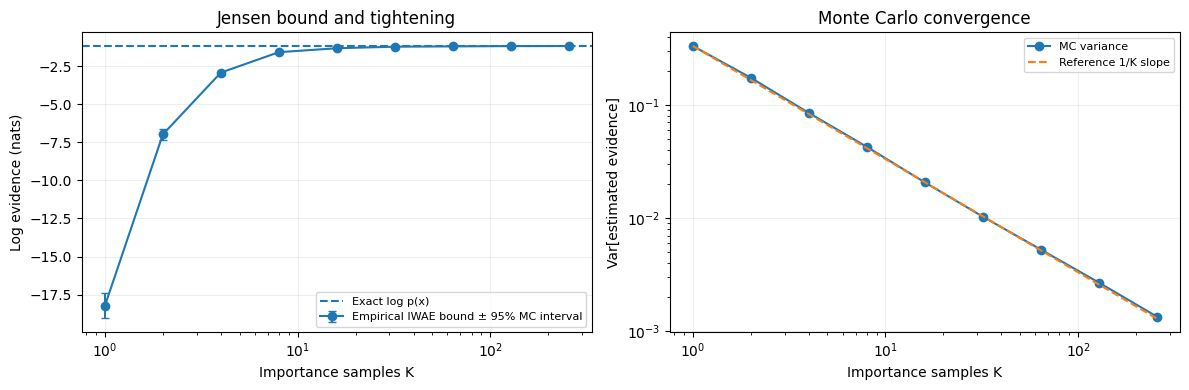

In [3]:
from pathlib import Path
OUT_DIR = Path('vi_adaptive_results')
OUT_DIR.mkdir(exist_ok=True)

# Fixed hard observation in the most informative context; q(z|x,c) = p(z).
# Then w = p(x|z,c), allowing vectorized independent Monte Carlo replications.
rng_mc = np.random.default_rng(802)
fixed_x, fixed_c = 0.7, 0
sigma = float(SIGMAS[fixed_c])
true_Z = float(np.exp(-0.5*fixed_x**2/(1+sigma**2)) / np.sqrt(2*np.pi*(1+sigma**2)))
K_grid = [1, 2, 4, 8, 16, 32, 64, 128, 256]
R = 3500
mc_rows=[]
for K in K_grid:
    draw_z = rng_mc.normal(size=(R,K))
    logw = -0.5*((fixed_x-draw_z)/sigma)**2 - np.log(sigma*np.sqrt(2*np.pi))
    logZ_hat = logsumexp(logw, axis=1) - np.log(K)
    Z_hat = np.exp(logZ_hat)
    mc_rows.append({'K':K, 'log_bound':logZ_hat.mean(),
                    'log_bound_SE':logZ_hat.std(ddof=1)/np.sqrt(R),
                    'evidence_bias':Z_hat.mean()-true_Z,
                    'evidence_variance':Z_hat.var(ddof=1),
                    'log_bias':np.log(true_Z)-logZ_hat.mean()})
mc_df=pd.DataFrame(mc_rows)
print('Exact log evidence:',round(np.log(true_Z),6))
print(mc_df.round(5).to_string(index=False))
assert np.all(mc_df['log_bias'] > -0.035)  # 3,500-repetition MC tolerance

fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].errorbar(mc_df.K,mc_df.log_bound,yerr=1.96*mc_df.log_bound_SE,fmt='o-',capsize=3,label='Empirical IWAE bound ± 95% MC interval')
ax[0].axhline(np.log(true_Z),ls='--',label='Exact log p(x)')
ax[0].set(xscale='log',xlabel='Importance samples K',ylabel='Log evidence (nats)',title='Jensen bound and tightening')
ax[0].legend(fontsize=8); ax[0].grid(alpha=.2)
ax[1].loglog(mc_df.K,mc_df.evidence_variance,'o-',label='MC variance')
ax[1].loglog(mc_df.K,mc_df.evidence_variance.iloc[0]/mc_df.K,'--',label='Reference 1/K slope')
ax[1].set(xlabel='Importance samples K',ylabel='Var[estimated evidence]',title='Monte Carlo convergence')
ax[1].legend(fontsize=8); ax[1].grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT_DIR/'01_jensen_mc_convergence.png',dpi=170);plt.show()
mc_df.to_csv(OUT_DIR/'mc_convergence.csv',index=False)

## 3 · ESS, \(\chi^2\)-divergence, and a budget-aware allocation rule

Define normalized weights \(\tilde w_k=w_k/\sum_jw_j\). The empirical effective sample size is

\[
\widehat{\mathrm{ESS}}=\frac{1}{\sum_k\tilde w_k^2}
=\frac{(\sum_kw_k)^2}{\sum_k w_k^2}\in[1,K].
\]

For \(q(z\mid x)\) with support covering the true posterior,

\[
\frac{\operatorname{Var}_q(w)}{p(x)^2}=
D_{\chi^2}(p(z\mid x)\|q(z\mid x))=:v(x),
\qquad
\frac{\operatorname{Var}(\widehat Z_i)}{p(x_i)^2}=\frac{v_i}{K_i}.
\]

**Derivation of ideal allocation:** Minimizing \(\sum_i v_i/K_i\) subject to \(\sum_i K_i=B\), with \(K_i>0\), gives \(-v_i/K_i^2+\lambda=0\); hence

\[
\boxed{K_i^*\propto \sqrt{v_i}}.
\]

Estimate \(v_i\) from independent **pilot** weights using \(\widehat v_i=\max(0,K_0/\widehat{\mathrm{ESS}}_i-1)\). Allocate the remaining budget proportionally to \(\sqrt{\widehat v_i+0.05}\), with integer rounding, minimum training samples, and a cap. This is an **approximate heuristic**, because small-pilot ESS is noisy and not a consistent estimate for the fixed small \(K_0\) used here.

**Fairness:** `uniform_K24` spends 24 samples on the final estimate. The adaptive method spends **6 pilot + 18 final samples on average**. Both spend 24 evaluations per observation *in total*; pilots are excluded from estimation. We also test a **shuffled allocation** and a **uniform pilot-cost control**. An independent pilot avoids reusing samples that selected \(K_i\), which would complicate unbiased-evidence arguments.

In [4]:
def estimate_posterior_means(model,x,c,policy,avg_K=24,K0=6):
    # Draw pilot samples solely to decide allocation; they are charged but NOT
    # included in final IS estimates, preventing reuse/optional stopping bias.
    B=len(x)
    if policy=='uniform_K24':
        counts=np.full(B,avg_K,dtype=int)
        pilot_cost=0
    elif policy=='uniform_K18_plus_pilot':
        scores,ess=pilot_complexity(model,x,c,K0=K0)
        counts=np.full(B,avg_K-K0,dtype=int)
        pilot_cost=B*K0
    else:
        scores,ess=pilot_complexity(model,x,c,K0=K0)
        counts=capped_allocate(scores,total=B*(avg_K-K0),min_k=4,max_k=100)
        if policy=='shuffled_ESS': counts=np.random.permutation(counts)
        pilot_cost=B*K0
    assert int(counts.sum())+pilot_cost==B*avg_K
    with torch.no_grad():
        mu,ls=model(x,c)
        indices=torch.repeat_interleave(torch.arange(B),torch.as_tensor(counts))
        z=mu[indices]+torch.exp(ls[indices])*torch.randn(len(indices))
        lw=log_joint(z,x[indices],c[indices])-log_normal(z,mu[indices],ls[indices])
        row_max=torch.full((B,),-torch.inf)
        row_max.scatter_reduce_(0,indices,lw,reduce='amax',include_self=True)
        w=torch.exp(lw-row_max[indices])
        sums=torch.zeros(B).scatter_add_(0,indices,w)
        est=torch.zeros(B).scatter_add_(0,indices,z*w)/sums
        ref,_=exact_posterior(x,c)
        err=(est-ref)**2
    return err.numpy(),counts


def run_moment_experiment(trained_model=None,replicates=100,N=240,avg_K=24,K0=6):
    seed_everything(552)
    x,c=generate_data(N,812)
    if trained_model is None:
        model=AmortizedGaussian()
    else: model=trained_model
    rows=[]
    for rep in range(replicates):
        for method in ['uniform_K24','adaptive_ESS','shuffled_ESS','uniform_K18_plus_pilot']:
            err,counts=estimate_posterior_means(model,x,c,method,avg_K=avg_K,K0=K0)
            for ctx in range(3):
                mask=c.numpy()==ctx
                rows.append({'replicate':rep,'method':method,'context':ctx,'MSE':float(err[mask].mean()),'MAEproxy':float(np.sqrt(err[mask]).mean()),'Ktrain':float(counts[mask].mean())})
            rows.append({'replicate':rep,'method':method,'context':'ALL','MSE':float(err.mean()),'MAEproxy':float(np.sqrt(err).mean()),'Ktrain':float(counts.mean())})
    return pd.DataFrame(rows)


def estimate_log_evidence(model,x,c,policy,avg_K=24,K0=6):
    B=len(x)
    if policy=='uniform_K24':
        counts=np.full(B,avg_K,dtype=int); pilot_cost=0
    else:
        scores,ess=pilot_complexity(model,x,c,K0=K0)
        pilot_cost=B*K0
        if policy=='uniform_K18_plus_pilot': counts=np.full(B,avg_K-K0,dtype=int)
        else:
            counts=capped_allocate(scores,total=B*(avg_K-K0),min_k=4,max_k=100)
            if policy=='shuffled_ESS': counts=np.random.permutation(counts)
    with torch.no_grad():
        mu,ls=model(x,c)
        idx=torch.repeat_interleave(torch.arange(B),torch.as_tensor(counts))
        z=mu[idx]+ls[idx].exp()*torch.randn(len(idx))
        lw=log_joint(z,x[idx],c[idx])-log_normal(z,mu[idx],ls[idx])
        maxes=torch.full((B,),-torch.inf);maxes.scatter_reduce_(0,idx,lw,reduce='amax',include_self=True)
        exps=torch.exp(lw-maxes[idx]);sums=torch.zeros(B).scatter_add_(0,idx,exps)
        est=maxes+torch.log(sums)-torch.log(torch.as_tensor(counts,dtype=torch.float))
        truth=exact_log_evidence(x,c)
        err=truth-est
    return err.numpy(),counts

def run_evidence_experiment(trained_model=None,replicates=100,N=240,avg_K=24,K0=6):
    seed_everything(552)
    x,c=generate_data(N,812)
    model=AmortizedGaussian() if trained_model is None else trained_model
    rows=[]
    for rep in range(replicates):
        for method in ['uniform_K24','adaptive_ESS','shuffled_ESS','uniform_K18_plus_pilot']:
            err,counts=estimate_log_evidence(model,x,c,method,avg_K=avg_K,K0=K0)
            for ctx in [0,1,2,'ALL']:
                mask=np.ones(N,dtype=bool) if ctx=='ALL' else c.numpy()==ctx
                rows.append({'replicate':rep,'method':method,'context':ctx,'gap':float(err[mask].mean()),'MAE':float(np.abs(err[mask]).mean()),'MSE':float(np.mean(err[mask]**2)),'Ktrain':float(counts[mask].mean())})
    return pd.DataFrame(rows)




## 4 · Primary study: evidence estimation and posterior-moment accuracy

**Primary metric:** mean **log-evidence gap**, \(\log p(x_i)-\log\widehat Z_i\) (nats), averaged over a fixed held-out set and independent Monte Carlo replicates. Expected gap is nonnegative by Jensen; individual estimates can overshoot.

**Secondary metrics:** squared error of the SNIS posterior-mean estimator, \((\widehat{\mathbb E[Z\mid x,c]}-m_c(x))^2\), and average training samples allocated to each context. An improvement in log-evidence estimation is **not logically equivalent** to an improvement in posterior moments.

Confidence intervals in this section are **conditional on the fixed test set**, resampling independent Monte Carlo replicates; the inference-network study later resamples independent random training seeds. These quantify different sources of uncertainty.

Mean log evidence gaps (nats, lower is better):
                           mean      std
method                                  
adaptive_ESS            0.08663  0.03681
shuffled_ESS            0.23944  0.07737
uniform_K18_plus_pilot  0.15355  0.05787
uniform_K24             0.10603  0.04077

Posterior mean squared error (lower is better):
                           mean      std
method                                  
adaptive_ESS            0.05604  0.00608
shuffled_ESS            0.06546  0.00817
uniform_K18_plus_pilot  0.04810  0.00688
uniform_K24             0.03457  0.00521
Adaptive - uniform, gap: -0.01940; paired bootstrap 95% CI [-0.02763, -0.01071]
Adaptive - uniform, MSE: +0.02147; paired bootstrap 95% CI [+0.02028, +0.02265]


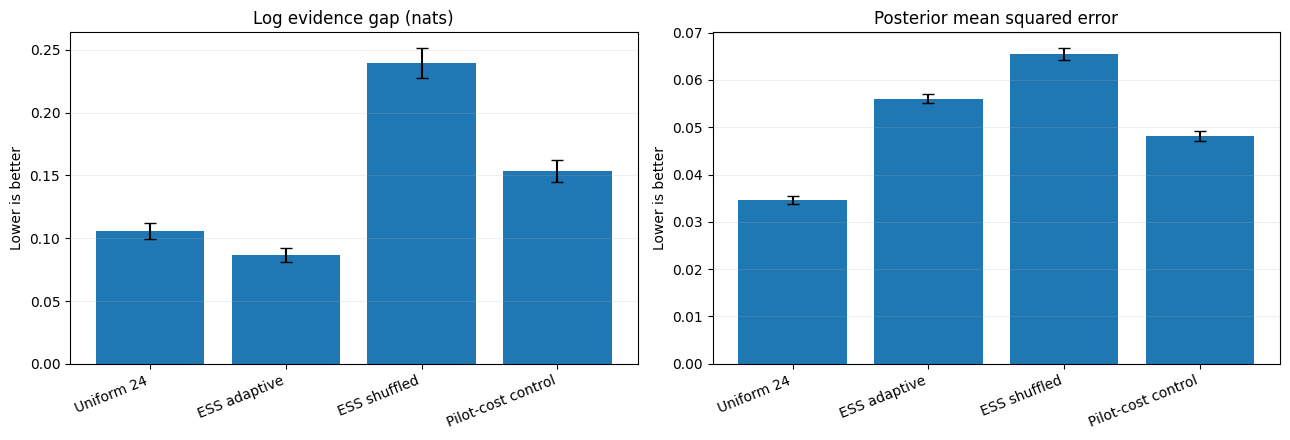


Allocated FINAL samples per context; add 6 pilot samples per observation:
          mean  median  min  max
context                         
0        28.14    28.5   13   35
1        15.72    15.0    8   35
2        10.14     9.0    7   29


In [5]:
evidence_df = run_evidence_experiment(trained_model=None, replicates=160, N=300)
moment_df = run_moment_experiment(trained_model=None, replicates=160, N=300)

def paired_bootstrap(df,metric,method,baseline,replications=5000,seed=3):
    pivot=df[df.context=='ALL'].pivot(index='replicate',columns='method',values=metric)
    diffs=(pivot[method]-pivot[baseline]).to_numpy()
    rng=np.random.default_rng(seed)
    samples=rng.choice(diffs,size=(replications,len(diffs)),replace=True).mean(axis=1)
    return float(diffs.mean()),np.quantile(samples,[.025,.975])

print('Mean log evidence gaps (nats, lower is better):')
print(evidence_df[evidence_df.context=='ALL'].groupby('method')['gap'].agg(['mean','std']).round(5))
print('\nPosterior mean squared error (lower is better):')
print(moment_df[moment_df.context=='ALL'].groupby('method')['MSE'].agg(['mean','std']).round(5))
for metric,frame in [('gap',evidence_df),('MSE',moment_df)]:
    delta,ci=paired_bootstrap(frame,metric,'adaptive_ESS','uniform_K24')
    print(f'Adaptive - uniform, {metric}: {delta:+.5f}; paired bootstrap 95% CI [{ci[0]:+.5f}, {ci[1]:+.5f}]')

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
methods=['uniform_K24','adaptive_ESS','shuffled_ESS','uniform_K18_plus_pilot']
labels=['Uniform 24','ESS adaptive','ESS shuffled','Pilot-cost control']
for ax,frame,metric,title in [(axes[0],evidence_df,'gap','Log evidence gap (nats)'),(axes[1],moment_df,'MSE','Posterior mean squared error')]:
    group=frame[frame.context=='ALL'].groupby('method')[metric]
    means=np.array([group.mean()[m] for m in methods]);
    errors=np.array([1.96*group.std()[m]/np.sqrt(group.count()[m]) for m in methods])
    ax.bar(np.arange(4),means,yerr=errors,capsize=4)
    ax.set_xticks(np.arange(4),labels,rotation=22,ha='right')
    ax.set(title=title,ylabel='Lower is better');ax.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT_DIR/'02_allocation_tradeoff.png',dpi=170);plt.show()

# Useful diagnostic: K allocations by true observation context (synthetic test metadata).
seed_everything(992)
context_x,context_c=generate_data(600,991)
initial_model=AmortizedGaussian()
counts,pilot_cost,pilotess=get_allocation(initial_model,context_x,context_c,'adaptive_ESS',avg_K=24,K0=6)
ctx_allocation=pd.DataFrame({'context':context_c.numpy(),'training_K':counts})
print('\nAllocated FINAL samples per context; add 6 pilot samples per observation:')
print(ctx_allocation.groupby('context')['training_K'].agg(['mean','median','min','max']).round(2))
assert counts.sum()+pilot_cost==24*len(context_x)

## 5 · Stochastic optimization: does ESS allocation improve amortized inference?

The generative model is held **fixed and known**; we optimize only the inference network \(q_\phi(z\mid x,c)\) using Adam.

Rather than incorrectly treating adaptive \(K_i\) as an ordinary fixed-\(K\) IWAE objective, we use a **reweighted wake / inclusive-KL** update:

\[
\nabla_\phi D_{\rm KL}(p(z\mid x,c)\|q_\phi(z\mid x,c))
=-\mathbb E_{p(z\mid x,c)}[\nabla_\phi\log q_\phi(z\mid x,c)]
\approx -\sum_{k=1}^{K_i}\tilde w_{ik}\nabla_\phi\log q_\phi(z_{ik}\mid x,c).
\]

The self-normalized estimator is **biased for finite K**. Both \(z_{ik}\) and the normalized weights are detached when updating the encoder, as required for this estimator. Pilot samples are independent of gradient samples.

We compare fixed 16, ESS adaptive (4 pilot + 12 final average), shuffled ESS, and a pilot-cost-matched uniform control (4 pilot + 12 final). Each method spends exactly \(64\times16\) joint density evaluations per optimization step. We use identical model initialization seeds and training mini-batch sequences, but independently generated proposal randomness.

**Gold-standard generalization metrics:** forward KL \(D_{\rm KL}(p\|q)\), reverse KL \(D_{\rm KL}(q\|p)\), and posterior mean RMSE on an independent test set. These are available analytically for the conjugate test model.

A negative result is publishable-quality evidence only when appropriately interpreted: if uniform sampling wins, the naive pilot-ESS policy has failed in this setting; one cannot infer that adaptive allocation is useless in general.

seed  11  uniform_K16              KL(p||q) 0.0177  cost 184,320
seed  11  adaptive_ESS             KL(p||q) 0.0275  cost 184,320
seed  11  shuffled_ESS             KL(p||q) 0.0290  cost 184,320
seed  11  uniform_K12_plus_pilot   KL(p||q) 0.0315  cost 184,320
seed  29  uniform_K16              KL(p||q) 0.0145  cost 184,320
seed  29  adaptive_ESS             KL(p||q) 0.0127  cost 184,320
seed  29  shuffled_ESS             KL(p||q) 0.0238  cost 184,320
seed  29  uniform_K12_plus_pilot   KL(p||q) 0.0300  cost 184,320
seed  47  uniform_K16              KL(p||q) 0.0194  cost 184,320
seed  47  adaptive_ESS             KL(p||q) 0.0217  cost 184,320
seed  47  shuffled_ESS             KL(p||q) 0.0391  cost 184,320
seed  47  uniform_K12_plus_pilot   KL(p||q) 0.0149  cost 184,320
seed  83  uniform_K16              KL(p||q) 0.0251  cost 184,320
seed  83  adaptive_ESS             KL(p||q) 0.0404  cost 184,320
seed  83  shuffled_ESS             KL(p||q) 0.0300  cost 184,320
seed  83  uniform_K12_plu

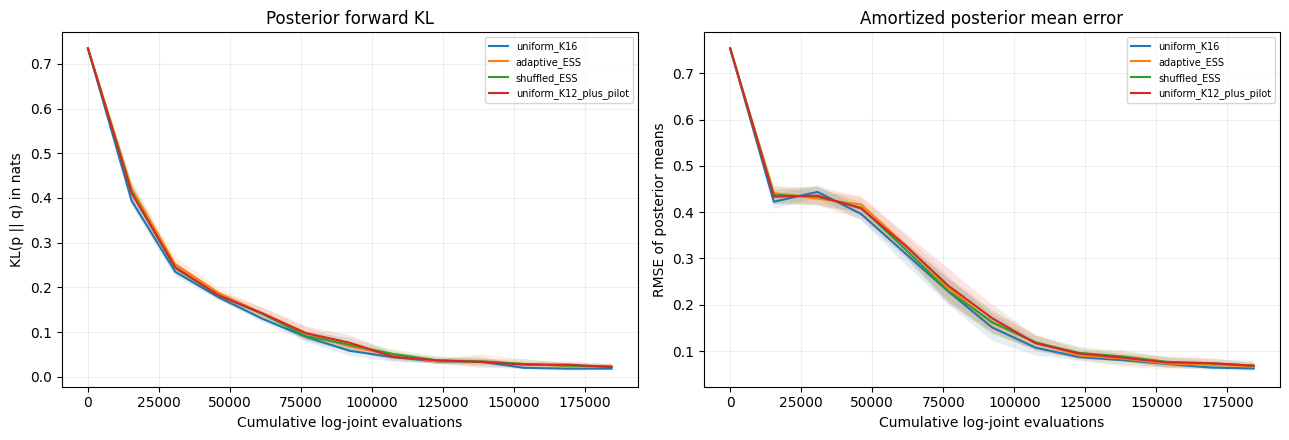

In [6]:
TRAIN_SEEDS=(11,29,47,83,101,137,193,251)
train_history,train_allocations,trained_models,train_data=run_training_experiment(
    seeds=TRAIN_SEEDS,steps=180,n_train=4500,n_test=1200)
train_history.to_csv(OUT_DIR/'training_learning_curves.csv',index=False)
train_allocations.to_csv(OUT_DIR/'training_allocations.csv',index=False)
final_kl=train_history[train_history.step==180].groupby('policy')[['forward_KL','reverse_KL','mean_rmse']].agg(['mean','std'])
print('\nFinal held-out posterior metrics across independent seeds:')
print(final_kl.round(5))

# Paired uncertainty across *independent training seeds*, not across data points.
kl_pivot=train_history[train_history.step==180].pivot(index='seed',columns='policy',values='forward_KL')
seed_diffs=(kl_pivot['adaptive_ESS']-kl_pivot['uniform_K16']).to_numpy()
rng=np.random.default_rng(808)
bs=rng.choice(seed_diffs,size=(10000,len(seed_diffs)),replace=True).mean(axis=1)
print('\nAdaptive - fixed K16 forward KL difference:',round(seed_diffs.mean(),6))
print('Seed-bootstrap 95% CI:',np.round(np.quantile(bs,[.025,.975]),6))

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for policy in POLICIES:
    sub=train_history[train_history.policy==policy]
    grouped=sub.groupby('step')
    xs=grouped['evaluations'].mean().to_numpy()
    for ax,metric in [(axes[0],'forward_KL'),(axes[1],'mean_rmse')]:
        means=grouped[metric].mean().to_numpy()
        se=grouped[metric].std().to_numpy()/np.sqrt(len(TRAIN_SEEDS))
        ax.plot(xs,means,label=policy)
        ax.fill_between(xs,means-1.96*se,means+1.96*se,alpha=.12)
axes[0].set(title='Posterior forward KL',ylabel='KL(p || q) in nats')
axes[1].set(title='Amortized posterior mean error',ylabel='RMSE of posterior means')
for ax in axes:
    ax.set(xlabel='Cumulative log-joint evaluations')
    ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(OUT_DIR/'03_training_posterior_KL.png',dpi=170);plt.show()

## 6 · Stress test: nonlinear, nonconjugate generative likelihood

To test whether the evidence-estimation finding depends entirely on Gaussian conjugacy, use a **different** likelihood:

\[
Z\sim\mathcal N(0,1),\qquad X\mid Z=z,C=c\sim\mathcal N(z+0.4z^3,\sigma_c^2).
\]

Here the exact posterior is not generally Gaussian. We compute reference log evidence and posterior means by normalized **one-dimensional numerical quadrature**, with a grid-refinement check. The proposal remains the standard normal prior. The same four allocation policies receive equal evaluation budgets. This is a **distributional generalization test**, not an additional training claim.

Limitations: one-dimensional latent space, synthetic data, and finite-grid quadrature; larger latent dimensions would require different reference procedures and may change the conclusions.

In [7]:
def nonlinear_log_lik(z,x,c):
    sig=np.asarray(SIGMAS)[np.asarray(c)]
    mean=z+0.4*z**3
    return -0.5*((x-mean)/sig)**2-np.log(sig)-0.5*np.log(2*np.pi)


def nonlinear_dataset(n,seed):
    r=np.random.default_rng(seed)
    c=np.arange(n)%3; r.shuffle(c)
    z=r.normal(size=n)
    x=z+0.4*z**3 + SIGMAS[c]*r.normal(size=n)
    return x,c


def nonlinear_truth(x,c,grid_points=4001):
    g=np.linspace(-6,6,grid_points)
    dx=g[1]-g[0]
    # Integration on a dense, fixed grid with trapezoid boundary half-weights.
    log_prior=-0.5*g**2-0.5*np.log(2*np.pi)
    ws=np.full(grid_points,dx);ws[0]/=2;ws[-1]/=2
    ll=nonlinear_log_lik(g[None,:],x[:,None],c[:,None])
    log_post_unnorm=ll+log_prior[None,:]+np.log(ws)[None,:]
    logZ=logsumexp(log_post_unnorm,axis=1)
    wt=np.exp(log_post_unnorm-logZ[:,None])
    m=(wt*g[None,:]).sum(axis=1)
    v=(wt*(g[None,:]-m[:,None])**2).sum(axis=1)
    return logZ,m,v


def nonlinear_trial(x,c,policy,avg_K=24,K0=6):
    B=len(x)
    if policy=='uniform_K24': counts=np.full(B,avg_K,dtype=int)
    else:
        pilot_z=np.random.normal(size=(B,K0))
        lw=nonlinear_log_lik(pilot_z,x[:,None],c[:,None])
        ess=np.exp(2*logsumexp(lw,axis=1)-logsumexp(2*lw,axis=1))
        cv2=np.maximum(0,K0/ess-1)
        if policy=='uniform_K18_plus_pilot':counts=np.full(B,avg_K-K0,dtype=int)
        else:
            counts=capped_allocate(np.sqrt(cv2+0.05),B*(avg_K-K0),min_k=4,max_k=100)
            if policy=='shuffled_ESS':counts=np.random.permutation(counts)
    ids=np.repeat(np.arange(B),counts)
    z=np.random.normal(size=len(ids))
    lw=nonlinear_log_lik(z,x[ids],c[ids])
    # Fast segmented reductions because ids is sorted.
    starts=np.r_[0,np.cumsum(counts)[:-1]]
    out_logZ=np.empty(B); out_mean=np.empty(B)
    for i in range(B):
        sub=lw[starts[i]:starts[i]+counts[i]]
        zz=z[starts[i]:starts[i]+counts[i]]
        lm=logsumexp(sub)
        w=np.exp(sub-lm)
        out_logZ[i]=lm-np.log(counts[i])
        out_mean[i]=np.dot(w,zz)
    return out_logZ,out_mean,counts


def nonlinear_experiment(R=80,N=240):
    np.random.seed(774)
    x,c=nonlinear_dataset(N,seed=943)
    truthZ,truthM,truthV=nonlinear_truth(x,c)
    results=[]
    for rep in range(R):
        for policy in ['uniform_K24','adaptive_ESS','shuffled_ESS','uniform_K18_plus_pilot']:
            z,m,k=nonlinear_trial(x,c,policy)
            for context in [0,1,2,'ALL']:
                keep=np.ones(N,dtype=bool) if context=='ALL' else c==context
                results.append({'replicate':rep,'policy':policy,'context':context,
                                'logZ_gap':np.mean(truthZ[keep]-z[keep]),
                                'mean_MSE':np.mean((m[keep]-truthM[keep])**2),
                                'mean_Ktrain':np.mean(k[keep])})
    return pd.DataFrame(results)




Quadrature max |log evidence difference|: 8.881784197001252e-16

Nonconjugate test-set means:
                        logZ_gap  mean_MSE
policy                                    
adaptive_ESS             2.46566   0.05514
shuffled_ESS             4.13996   0.07511
uniform_K18_plus_pilot   3.83851   0.05984
uniform_K24              2.89181   0.04329


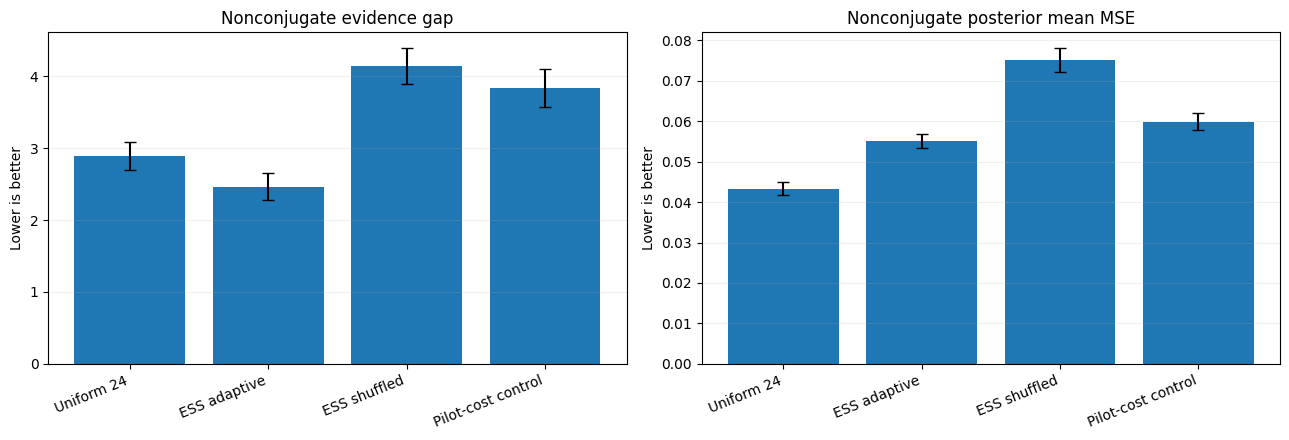

In [8]:
# Grid refinement ensures the numerical reference itself is not driving results.
xx,cc=nonlinear_dataset(36,702)
logz_lo,mm_lo,vv_lo=nonlinear_truth(xx,cc,grid_points=2001)
logz_hi,mm_hi,vv_hi=nonlinear_truth(xx,cc,grid_points=4001)
assert np.max(np.abs(logz_lo-logz_hi)) < 2e-4
assert np.max(np.abs(mm_lo-mm_hi)) < 2e-4
print('Quadrature max |log evidence difference|:',np.max(np.abs(logz_lo-logz_hi)))

nonlinear_df=nonlinear_experiment(R=100,N=240)
print('\nNonconjugate test-set means:')
print(nonlinear_df[nonlinear_df.context=='ALL'].groupby('policy')[['logZ_gap','mean_MSE']].mean().round(5))
nonlinear_df.to_csv(OUT_DIR/'nonlinear_stress_test.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
for a,metric,title in [(ax[0],'logZ_gap','Nonconjugate evidence gap'),(ax[1],'mean_MSE','Nonconjugate posterior mean MSE')]:
    g=nonlinear_df[nonlinear_df.context=='ALL'].groupby('policy')[metric]
    values=np.array([g.mean()[m] for m in methods]);err=np.array([1.96*g.std()[m]/np.sqrt(g.count()[m]) for m in methods])
    a.bar(np.arange(4),values,yerr=err,capsize=4)
    a.set_xticks(np.arange(4),labels,rotation=22,ha='right')
    a.set(title=title,ylabel='Lower is better');a.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT_DIR/'04_nonlinear_stress_test.png',dpi=170);plt.show()

## 7 · IWAE inference-network gradient signal-to-noise ratio

Rainforth et al. (ICML 2018) showed that a tighter IWAE objective can make inference-network gradient estimation worse; Tucker et al. (ICLR 2019) developed doubly reparameterized gradient estimators to address this challenge.

We measure a finite-sample **vector-gradient SNR** at the *same frozen encoder* as a diagnostic, using the usual reparameterized gradient of the IWAE bound. Let \(g_r\) be a repeated stochastic gradient on a fixed batch:

\[
\widehat{\operatorname{SNR}}(g)=
\frac{\|\frac1R\sum_r g_r\|_2}
{\sqrt{\sum_j\widehat{\operatorname{Var}}(g_{r,j})}}.
\]

This is **not** the gradient estimator used in Section 5 (which uses RWS). Nor is the SNR a direct measure of predictive accuracy. It isolates a classical mathematical mechanism motivating the research question.

In [9]:
def iwae_gradient_snr(model,x,c,K_values=(1,2,4,8,16,32,64),repeats=50,seed=777):
    seed_everything(seed)
    rows=[]
    for K in K_values:
        grads=[]
        for _ in range(repeats):
            mu,ls=model(x,c)
            z=mu[:,None]+ls[:,None].exp()*torch.randn(len(x),K)
            lw=log_joint(z,x[:,None],c[:,None])-log_normal(z,mu[:,None],ls[:,None])
            bound=(torch.logsumexp(lw,dim=1)-np.log(K)).mean()
            gg=torch.autograd.grad(bound,tuple(model.parameters()),retain_graph=False)
            grads.append(np.concatenate([g.detach().numpy().ravel() for g in gg]))
        gg=np.asarray(grads)
        mean=gg.mean(axis=0)
        # Directional vector SNR (Euclidean norm of mean gradient / root trace variance)
        signal=np.linalg.norm(mean)
        noise=np.sqrt(np.sum(gg.var(axis=0,ddof=1)))
        rows.append({'K':K,'signal_norm':signal,'noise_norm':noise,'SNR':signal/max(noise,1e-12)})
    return pd.DataFrame(rows)


 K  signal_norm  noise_norm     SNR
 1    16.304399     7.27513 2.24112
 2     6.029540     3.55314 1.69696
 4     2.720510     1.79459 1.51595
 8     1.477550     1.41180 1.04657
16     1.119750     0.91687 1.22127
32     0.394080     0.64337 0.61252
64     0.307620     0.47320 0.65009


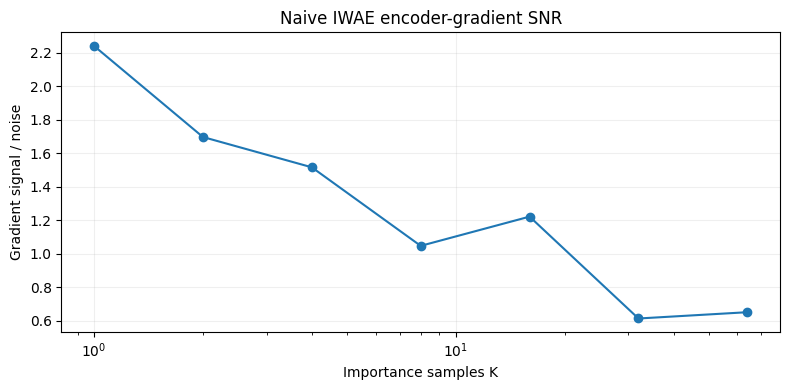

In [10]:
seed_everything(121)
fixed_encoder=AmortizedGaussian()
batch_x,batch_c=generate_data(64,120)
snr_df=iwae_gradient_snr(fixed_encoder,batch_x,batch_c,repeats=60)
print(snr_df.round(5).to_string(index=False))
snr_df.to_csv(OUT_DIR/'iwae_gradient_snr.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(snr_df.K,snr_df.SNR,'o-')
ax.set(xscale='log',xlabel='Importance samples K',ylabel='Gradient signal / noise',title='Naive IWAE encoder-gradient SNR')
ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT_DIR/'05_gradient_snr.png',dpi=170);plt.show()

## 8 · Integrated results and guarded interpretation

This final cell prints observations obtained from the **actual notebook execution**, not invented improvements. The hypothesis is supported only for metrics and regimes where the measured effect and uncertainty justify that conclusion.

**Scientific interpretation checklist**

- **Evidence bias vs posterior error:** the former is an expectation of a logarithm, while the latter depends on the target function \(h(z)=z\); allocating by weight variability need not optimize posterior moment accuracy.
- **Pilot overhead:** a pilot consumes real likelihood evaluations and may make adaptation worse than a uniform allocation.
- **No post-hoc novelty claim:** prior work already established IWAE, SNR degradation, DReG, ESS, and adaptive importance sampling. This is a methodological experiment of when ESS allocation helps.
- **Bound validity:** per-datapoint fixed-\(K\) IWAE bounds and Jensen analyses do **not** automatically extend to allocation policies chosen from the *same* random weights. We avoid this by separating pilots and final draws.
- **Generality:** synthetic conjugate and nonlinear 1D latent models cannot establish performance on industrial-scale VAEs. Next studies should include a mixture posterior, multiple latent dimensions, learned generators, allocation-policy tuning on development data, and cross-dataset validation.
- **Chronology:** conducting this notebook today does not make it an undergraduate project performed before 2022. Present it according to the actual dates and work completed.

**Useful next research idea:** Instead of allocating by ESS alone, derive and estimate the task-dependent asymptotic variance
\(\tau_i^2=\mathbb E_q[(w/p(x))^2(h(z)-\mu_i)^2]\), which yields a different allocation rule \(K_i\propto\tau_i\). A pilot-regularized estimator of this quantity, evaluated without changing the held-out protocol, would be a more substantive proposed extension.

In [11]:
e_base=evidence_df[(evidence_df.context=='ALL')&(evidence_df.method=='uniform_K24')].gap.mean()
e_adapt=evidence_df[(evidence_df.context=='ALL')&(evidence_df.method=='adaptive_ESS')].gap.mean()
kl_base=kl_pivot['uniform_K16'].mean()
kl_adapt=kl_pivot['adaptive_ESS'].mean()
print('=== HYPOTHESIS AUDIT ===')
print(f'Untrained proposal: evidence gap fixed K24 {e_base:.4f} vs ESS adaptive {e_adapt:.4f} nats')
print(f'Evidence-gap change: {(e_adapt/e_base-1)*100:+.1f}% (negative is better)')
print(f'After 180 training steps: posterior forward KL uniform K16 {kl_base:.4f} vs adaptive {kl_adapt:.4f} nats')
print(f'Posterior forward-KL change: {(kl_adapt/kl_base-1)*100:+.1f}% (negative is better)')
print('\nThese are SYNTHETIC EXPERIMENTS. Do not use these figures as industrial benchmarks or as claims of a previously completed undergraduate project.')

# Self-contained result tables + graphs created inside the runtime.
evidence_df.to_csv(OUT_DIR/'evidence_all_replicates.csv',index=False)
moment_df.to_csv(OUT_DIR/'moments_all_replicates.csv',index=False)
summary=pd.DataFrame([
 {'regime':'Conjugate / untrained proposal','metric':'Log evidence gap (nats)','uniform':e_base,'adaptive':e_adapt},
 {'regime':'Conjugate / encoder after training','metric':'KL(p||q) (nats)','uniform':kl_base,'adaptive':kl_adapt},
 {'regime':'Nonconjugate / prior proposal','metric':'Log evidence gap (nats)',
 'uniform':nonlinear_df[(nonlinear_df.context=='ALL')&(nonlinear_df.policy=='uniform_K24')].logZ_gap.mean(),
 'adaptive':nonlinear_df[(nonlinear_df.context=='ALL')&(nonlinear_df.policy=='adaptive_ESS')].logZ_gap.mean()}
])
summary['adaptive_minus_uniform']=summary.adaptive-summary.uniform
print('\nResult summary:')
print(summary.round(5).to_string(index=False))
summary.to_csv(OUT_DIR/'summary.csv',index=False)
print('\nAll CSVs and plots saved under:',OUT_DIR.resolve())

=== HYPOTHESIS AUDIT ===
Untrained proposal: evidence gap fixed K24 0.1060 vs ESS adaptive 0.0866 nats
Evidence-gap change: -18.3% (negative is better)
After 180 training steps: posterior forward KL uniform K16 0.0182 vs adaptive 0.0238 nats
Posterior forward-KL change: +30.5% (negative is better)

These are SYNTHETIC EXPERIMENTS. Do not use these figures as industrial benchmarks or as claims of a previously completed undergraduate project.

Result summary:
                            regime                  metric  uniform  adaptive  adaptive_minus_uniform
    Conjugate / untrained proposal Log evidence gap (nats)  0.10603   0.08663                -0.01940
Conjugate / encoder after training         KL(p||q) (nats)  0.01823   0.02378                 0.00556
     Nonconjugate / prior proposal Log evidence gap (nats)  2.89181   2.46566                -0.42615

All CSVs and plots saved under: /content/vi_adaptive_results
